# 06 · Per-question switching between Qwen 3B and 7B — Set 2a (router v2) (GPU, ~25–30 min)

**Set 2a:** the Set 1 results table (16 setups, no chain-of-thought), with the router rebuilt. Compared against Set 1's router v1 run (`runs/switching/20260929-100917_A100`), this isolates the effect of the router fixes.

**Router v2** (Set 2) changes, each fixing a Set 1 flaw:

| Set 1 (router v1) | Set 2 (router v2) |
|---|---|
| 7–16 possible setups as routes | a short route menu: `S1-S5`, `S1-L5`, `L1-L5` |
| agent's rule list grew each round (31 / 84 rules) | the new list **replaces** the old; at most `MAX_RULES` lines, **enforced** when parsing |
| conditions on topics, free text | only `IF <feature> <op> <value> [AND …] THEN <route>` over named, checkable features |
| a 3B model applied the rules | rules applied **exactly** by code, and separately by the 3B (fidelity reported) |
| classifier labels dominated by questions nobody solves | **cost-weighted** classifier: questions where the route makes no difference carry no weight |
| — | agent sees route accuracy by feature value, and the questions where routes disagree first |

`ROUTER_VERSION = 1` reruns the Set 1 router exactly.
Also reported: each route used alone, the dev-optimal global setup (over the whole table), the AgentTTS picks from notebook 05, and two hindsight oracles.

Output: `runs/<EXPERIMENT>/<timestamp>_<GPU>/` (`summary.md`, `policies.csv`, `test_decisions.csv`, `rules_v2_*.txt`, `nl_rules_log.json`, plot, `speedcheck.csv`).

In [4]:
# ==== settings ====
PROJECT_DIR     = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
STEP0_EXPERIMENT = "env_qwen_hotpotqa"
STEP0_RUN_DIR   = ""          # empty = latest finished run in runs/<STEP0_EXPERIMENT>; or paste a run folder
SCRIPT1_RUN_DIR = "auto"      # "auto" = latest notebook-05 run on the same table; "" = leave out
ROUTER_VERSION  = 2           # 2 = Set 2 router; 1 = the Set 1 router
ROUTES          = ['S1-S5', 'S1-L5', 'L1-L5']   # router v2 route menu (cheapest first)
EXPERIMENT      = "set2a_switching" if ROUTER_VERSION == 2 else "switching"
AGENT_MODEL_DIR = "Qwen2.5-7B-Instruct"   # agent LLM; "Qwen3-4B" (downloaded in 00) + THINKING = True for thinking mode
THINKING = False
LARGE_MODEL_DIR = "Qwen2.5-7B-Instruct"
LAMBDAS    = [0.0, 0.01, 0.03, 0.1]   # accuracy-vs-cost trade-offs (utility = EM - lambda x cost/cheapest)
NL_LAMBDAS = [0.03]                   # trade-offs for the NL rule router (each costs NL_ROUNDS agent calls x 2 settings)
NL_ROUNDS, MAX_RULES, MAX_EVIDENCE = 5, 8, 90
SPEEDCHECK, SPEED_N = True, 10        # live timing of the main policies on SPEED_N test questions
TIME_LIMIT_MIN = 55
RESUME_RUN_DIR = None
DRY_RUN = False

In [5]:
import subprocess, sys, os, json, shutil, time
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv,noheader 2>/dev/null",
                     shell=True, capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "none")
if not DRY_RUN:
    assert gpu, "No GPU: Runtime -> Change runtime type -> A100 GPU (or set DRY_RUN = True)."
    if "T4" in gpu:
        raise SystemExit("This runtime has a T4, which cannot run this: the 7B model alone (15 GB) does not fit in its memory.\n"
                         "Runtime -> Change runtime type -> A100 GPU (or G4 / L4) -> Save, then run all cells again.")
    if "A100" not in gpu and "G4" not in gpu and "RTX PRO 6000" not in gpu:
        print("Note: planned for an A100 or G4; this GPU works but timings will differ.")
GPU_TAG = "cpu" if not gpu else gpu.split(",")[0].replace("NVIDIA", "").replace("Tesla", "").strip().split()[0].split("-")[0]
T_START = time.time()

GPU: NVIDIA A100-SXM4-40GB, 40960 MiB, 8.0


In [6]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [7]:
import glob
if not STEP0_RUN_DIR:   # empty = the latest finished results-table run in runs/<STEP0_EXPERIMENT> (dry runs skipped)
    done = [p for p in sorted(glob.glob(f"{PROJECT_DIR}/runs/{STEP0_EXPERIMENT}/*/table/per_question.csv")) if "_dryrun" not in p or DRY_RUN]
    assert done, f"No finished results table in runs/{STEP0_EXPERIMENT} - run notebook {'04b' if 'cot' in STEP0_EXPERIMENT else '04'} first."
    STEP0_RUN_DIR = os.path.dirname(os.path.dirname(done[-1]))
assert os.path.exists(f"{STEP0_RUN_DIR}/table/per_question.csv"), f"{STEP0_RUN_DIR} is not a finished results-table run."
print("Results table:", STEP0_RUN_DIR)
DATA_DIR = json.load(open(f"{STEP0_RUN_DIR}/config.json"))["data_dir"]

Results table: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/env_qwen_hotpotqa/20260928-155333_A100


In [8]:
if SCRIPT1_RUN_DIR == "auto":   # latest AgentTTS run (notebook 05) built on this same results table
    SCRIPT1_RUN_DIR = ""
    runs = sorted(glob.glob(f"{PROJECT_DIR}/runs/*/*/agenttts_runs.csv"), key=lambda p: os.path.basename(os.path.dirname(p)))
    for p in runs:
        d = os.path.dirname(p)
        c = json.load(open(f"{d}/config.json"))
        if ("_dryrun" not in d or DRY_RUN) and c.get("step0_run_dir") == STEP0_RUN_DIR and bool(c.get("allow_cot")) == False:
            SCRIPT1_RUN_DIR = d
print("AgentTTS results from notebook 05:", SCRIPT1_RUN_DIR or "none yet (the comparison will leave them out)")

AgentTTS results from notebook 05: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/agenttts_global/20260929-094802_A100


In [9]:
from datetime import datetime
from zoneinfo import ZoneInfo
if RESUME_RUN_DIR:
    RUN_DIR = RESUME_RUN_DIR
else:
    stamp = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
    RUN_DIR = f"{PROJECT_DIR}/runs/{EXPERIMENT}/{stamp}_{GPU_TAG}" + ("_dryrun" if DRY_RUN else "")
for sub in ["logs", "code"]:
    os.makedirs(f"{RUN_DIR}/{sub}", exist_ok=True)
print("Run folder:", RUN_DIR)
json.dump({"experiment": EXPERIMENT, "step0_run_dir": STEP0_RUN_DIR, "script1_run_dir": SCRIPT1_RUN_DIR,
           "router_version": ROUTER_VERSION, "routes": ROUTES, "agent": AGENT_MODEL_DIR, "thinking": THINKING,
           "lambdas": LAMBDAS, "nl_lambdas": NL_LAMBDAS, "nl_rounds": NL_ROUNDS, "max_rules": MAX_RULES, "max_evidence": MAX_EVIDENCE,
           "gpu": gpu, "dry_run": DRY_RUN}, open(f"{RUN_DIR}/config.json", "w"), indent=1)

Run folder: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/set2a_switching/20260929-125432_A100


In [10]:
BACKEND = "mock" if DRY_RUN else "vllm"
CODE = "/content/ssw.py"
shutil.copy(f"{PROJECT_DIR}/code/ssw.py", CODE)
shutil.copy(CODE, f"{RUN_DIR}/code/ssw.py")          # keep the exact code with the results

def minutes_left():
    return max(1.0, TIME_LIMIT_MIN - (time.time() - T_START) / 60)

def run_stage(args, log_name):
    """Runs one ssw.py command in a fresh process; streams output here and into logs/<log_name>."""
    cmd = [sys.executable, "-u", CODE] + [str(a) for a in args]
    t0 = time.time()
    with open(f"{RUN_DIR}/logs/{log_name}", "a") as log:
        log.write("\n$ " + " ".join(cmd) + "\n")
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            log.write(line)
            if any(k in line for k in ("it/s]", "s/it]", "INFO ", "(EngineCore")):
                continue                      # keep the notebook readable; everything is in the log file
            print(line, end="")
        p.wait()
    TIMES[log_name.replace(".log", "")] = round(time.time() - t0)
    json.dump(TIMES, open(f"{RUN_DIR}/logs/stage_times.json", "w"), indent=1)
    print(f"--- {log_name}: exit {p.returncode}, {time.time() - t0:.0f}s, {minutes_left():.0f} min left of the limit")
    if p.returncode != 0:
        raise RuntimeError(f"stage failed - see {RUN_DIR}/logs/{log_name}")
TIMES = {}

In [11]:
# vLLM runs only inside the stage processes, so no runtime restart is needed (~3-5 min)
if not DRY_RUN:
    !pip install -q vllm
    !pip uninstall -y -q torchaudio   # Colab's torchaudio is built for another CUDA version and breaks imports
    chk = subprocess.run([sys.executable, "-c", "from vllm import LLM; import vllm, torch; print('vLLM', vllm.__version__, '| torch', torch.__version__)"],
                         capture_output=True, text=True)
    print(chk.stdout or chk.stderr[-2000:])
    assert chk.returncode == 0, "vLLM does not import - Runtime -> Disconnect and delete runtime, then run again."
TIMES["install_vllm"] = round(time.time() - T_START)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.9/314.9 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 117.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 126.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.7/322.7 kB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 120.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 59.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 108.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 61.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7

In [12]:
LOCAL = "/content/models"
MODELS = {
    "S": {"id": "Qwen/Qwen2.5-3B-Instruct", "dir": "Qwen2.5-3B-Instruct", "params": 3.09e9, "nominal": 3e9},
    "L": {"id": "Qwen/Qwen2.5-7B-Instruct", "dir": LARGE_MODEL_DIR,       "params": 7.62e9, "nominal": 7e9},
}
_t = time.time()
for key in ["S", "L", AGENT_MODEL_DIR]:
    m = MODELS[key] if key in MODELS else {"dir": key}
    src, dst = f"{PROJECT_DIR}/models/{m['dir']}", f"{LOCAL}/{m['dir']}"
    m["path"] = dst
    if DRY_RUN:
        continue
    assert os.path.exists(f"{src}/config.json"), f"{src} missing - run 00_setup_download_qwen7b first."
    if not os.path.exists(f"{dst}/config.json"):
        print("copying", m["dir"], "to local disk ...")
        shutil.copytree(src, dst, dirs_exist_ok=True)
for m in MODELS.values():
    m["path"] = f"{LOCAL}/{m['dir']}"
json.dump(MODELS, open(f"{RUN_DIR}/models.json", "w"), indent=1)
TIMES["copy_models"] = round(time.time() - _t)
print(f"models ready in {time.time() - _t:.0f}s")
AGENT_PATH = f"{LOCAL}/{AGENT_MODEL_DIR}"

copying Qwen2.5-3B-Instruct to local disk ...
copying Qwen2.5-7B-Instruct to local disk ...
models ready in 452s


### Routers (agent and 3B rule reader share the GPU: 50% / 30% of memory)

In [13]:
run_stage(["switching", "--run_dir", RUN_DIR, "--data_dir", DATA_DIR, "--table_dir", f"{STEP0_RUN_DIR}/table",
           "--models_json", f"{RUN_DIR}/models.json", "--agent_path", AGENT_PATH, "--backend", BACKEND,
           "--router_version", ROUTER_VERSION, "--routes", *ROUTES, "--max_evidence", MAX_EVIDENCE,
           "--lambdas", *LAMBDAS, "--nl_lambdas", *NL_LAMBDAS, "--nl_rounds", NL_ROUNDS, "--max_rules", MAX_RULES,
           "--time_limit_min", minutes_left(), "--agent_max_tokens", 4096 if THINKING else 1536, "--max_model_len", 32768]
          + (["--thinking"] if THINKING else []) + (["--script1_dir", SCRIPT1_RUN_DIR] if SCRIPT1_RUN_DIR else []),
          "01_switching.log")

[05:05:38] router v2 | routes ['S1-S5', 'S1-L5', 'L1-L5'] | probe S1-S5 in menu
[05:10:39]   NL rules v2 | before running | lambda 0.03 | round 1: 6 rules (0 lines dropped), dev EM 0.310 at 1.11x (exact); 3B follows them on 90% of questions
[05:10:41]   NL rules v2 | before running | lambda 0.03 | round 2: 7 rules (0 lines dropped), dev EM 0.330 at 1.20x (exact); 3B follows them on 64% of questions
[05:10:42]   NL rules v2 | before running | lambda 0.03 | round 3: 8 rules (0 lines dropped), dev EM 0.360 at 1.25x (exact); 3B follows them on 86% of questions
[05:10:45]   NL rules v2 | before running | lambda 0.03 | round 4: 8 rules (0 lines dropped), dev EM 0.360 at 1.25x (exact); 3B follows them on 86% of questions
[05:10:47]   NL rules v2 | before running | lambda 0.03 | round 5: 8 rules (0 lines dropped), dev EM 0.360 at 1.25x (exact); 3B follows them on 86% of questions
[05:10:47]   NL rules v2 | before running: 3B follows the chosen rules on 87% of test questions
[05:11:08]   NL rul

### Live speed check (3B and 7B loaded together, one question at a time)

In [14]:
if SPEEDCHECK and minutes_left() > 8:
    run_stage(["speedcheck", "--run_dir", RUN_DIR, "--data_dir", DATA_DIR, "--models_json", f"{RUN_DIR}/models.json",
               "--switching_dir", RUN_DIR, "--n_questions", SPEED_N, "--backend", BACKEND], "02_speedcheck.log")
else:
    print("speed check skipped")

[05:15:26]   timed always L1-L5 (retrieval 7B x1, answer 7B x5) (fixed)
[05:16:00]   timed dev-optimal global config (fixed)
[05:16:32]   timed classifier (cost-weighted) (before running)
[05:17:22]   timed cascade (agree<1.01 -> L1-L5) (after probe)
                                      policy        setting  lambda  questions   mean_s  median_s    p95_s  EM
always L1-L5 (retrieval 7B x1, answer 7B x5)          fixed     NaN         10 3.999595  2.836081 8.656136 0.5
               cascade (agree<1.01 -> L1-L5)    after probe    0.00         10 5.056297  4.665747 7.226893 0.4
                  classifier (cost-weighted) before running    0.00         10 3.213976  2.967367 5.423447 0.4
                   dev-optimal global config          fixed    0.03         10 3.373010  3.152443 5.431442 0.4
--- 02_speedcheck.log: exit 0, 305s, 32 min left of the limit


# Per-question switching (router v2) - 20260929-125432_A100

Test questions: 200. Costs include the probe (after-probe routers) and the rule-reading call (NL router). 'EM vs global' = test EM minus the dev-optimal global config at the same lambda, with a paired bootstrap 95% interval.

| policy | setting | lambda | test EM | test F1 | TFLOPs/q | cost vs cheapest | est. GPU s/q | EM vs global [95% CI] | routes used |
|---|---|---|---|---|---|---|---|---|---|
| classifier (cost-weighted) | after probe | 0.0 | 0.525 | 0.619 | 67.5 | 3.06x | 0.91 | -0.020 [-0.060, +0.020] | L1-L5:98, S1-L5:97, S1-S5:5 |
| cascade (agree<1.01 -> L1-L5) | after probe | 0.0 | 0.545 | 0.660 | 81.7 | 3.71x | 1.03 | +0.000 [-0.025, +0.025] | L1-L5:200 |
| classifier (cost-weighted) | after probe | 0.01 | 0.505 | 0.600 | 62.1 | 2.81x | 0.84 | -0.040 [-0.085, +0.005] | L1-L5:86, S1-L5:85, S1-S5:29 |
| cascade (agree<1.01 -> L1-L5) | after probe | 0.01 | 0.545 | 0.660 | 81.7 | 3.71x | 1.03 | +0.000 [-0.025, +0.025] | L1-L5:200 |
| classifier (cost-weighted) | after probe | 0.03 | 0.465 | 0.575 | 56.2 | 2.55x | 0.77 | -0.080 [-0.125, -0.035] | L1-L5:74, S1-L5:68, S1-S5:58 |
| NL rules v2 (3B reads the rules) | after probe | 0.03 | 0.435 | 0.545 | 58.7 | 2.66x | 0.76 | -0.110 [-0.165, -0.060] | L1-L5:84, S1-L5:51, S1-S5:65 |
| NL rules v2 (applied exactly) | after probe | 0.03 | 0.525 | 0.628 | 74.9 | 3.40x | 0.96 | -0.020 [-0.050, +0.010] | L1-L5:167, S1-L5:17, S1-S5:16 |
| cascade (agree<1.01 -> L1-L5) | after probe | 0.03 | 0.545 | 0.660 | 81.7 | 3.71x | 1.03 | +0.000 [+0.000, +0.000] | L1-L5:200 |
| cascade (agree<0.4 -> L1-L5) | after probe | 0.1 | 0.320 | 0.447 | 32.5 | 1.47x | 0.49 | -0.100 [-0.160, -0.040] | L1-L5:31, S1-S5:169 |
| classifier (cost-weighted) | after probe | 0.1 | 0.345 | 0.468 | 36.4 | 1.65x | 0.53 | -0.075 [-0.135, -0.015] | L1-L5:37, S1-L5:11, S1-S5:152 |
| classifier (cost-weighted) | before running | 0.0 | 0.515 | 0.620 | 48.2 | 2.18x | 0.56 | -0.030 [-0.075, +0.015] | L1-L5:121, S1-L5:75, S1-S5:4 |
| classifier (cost-weighted) | before running | 0.01 | 0.505 | 0.613 | 48.9 | 2.22x | 0.57 | -0.040 [-0.085, +0.000] | L1-L5:127, S1-L5:70, S1-S5:3 |
| NL rules v2 (applied exactly) | before running | 0.03 | 0.345 | 0.451 | 27.9 | 1.27x | 0.41 | -0.200 [-0.265, -0.135] | S1-L5:108, S1-S5:92 |
| NL rules v2 (3B reads the rules) | before running | 0.03 | 0.345 | 0.442 | 29.5 | 1.34x | 0.41 | -0.200 [-0.260, -0.135] | S1-L5:114, S1-S5:86 |
| classifier (cost-weighted) | before running | 0.03 | 0.510 | 0.610 | 46.7 | 2.12x | 0.55 | -0.035 [-0.075, +0.005] | L1-L5:116, S1-L5:63, S1-S5:21 |
| classifier (cost-weighted) | before running | 0.1 | 0.325 | 0.437 | 28.8 | 1.30x | 0.42 | -0.095 [-0.150, -0.040] | L1-L5:24, S1-L5:25, S1-S5:151 |
| always S1-S5 (retrieval 3B x1, answer 3B x5) | fixed |  | 0.270 | 0.387 | 23.4 | 1.06x | 0.38 | -0.275 [-0.345, -0.200] | S1-S5:200 |
| AgentTTS agent (budget 54, seed 0) | fixed |  | 0.270 | 0.387 | 23.4 | 1.06x | 0.38 | -0.275 [-0.345, -0.200] | S1-S5:200 |
| AgentTTS agent (budget 85, seed 1) | fixed |  | 0.270 | 0.387 | 23.4 | 1.06x | 0.38 | -0.275 [-0.345, -0.200] | S1-S5:200 |
| AgentTTS agent (budget 54, seed 1) | fixed |  | 0.300 | 0.416 | 24.6 | 1.12x | 0.40 | -0.245 [-0.315, -0.175] | S3-S5:200 |
| AgentTTS agent (budget 54, seed 2) | fixed |  | 0.300 | 0.416 | 24.6 | 1.12x | 0.40 | -0.245 [-0.315, -0.175] | S3-S5:200 |
| AgentTTS agent (budget 85, seed 0) | fixed |  | 0.405 | 0.481 | 29.9 | 1.36x | 0.42 | -0.140 [-0.205, -0.070] | S3-L1:200 |
| always S1-L5 (retrieval 3B x1, answer 7B x5) | fixed |  | 0.420 | 0.514 | 32.1 | 1.45x | 0.43 | -0.125 [-0.185, -0.060] | S1-L5:200 |
| AgentTTS agent (budget 85, seed 2) | fixed |  | 0.420 | 0.514 | 32.1 | 1.45x | 0.43 | -0.125 [-0.185, -0.060] | S1-L5:200 |
| AgentTTS agent (budget 129, seed 2) | fixed |  | 0.470 | 0.563 | 56.1 | 2.54x | 0.62 | -0.075 [-0.120, -0.030] | L1-L1:200 |
| always L1-L5 (retrieval 7B x1, answer 7B x5) | fixed |  | 0.545 | 0.660 | 58.4 | 2.65x | 0.65 | +0.000 [-0.025, +0.025] | L1-L5:200 |
| AgentTTS agent (budget 129, seed 0) | fixed |  | 0.545 | 0.660 | 58.4 | 2.65x | 0.65 | +0.000 [-0.025, +0.025] | L1-L5:200 |
| AgentTTS agent (budget 129, seed 1) | fixed |  | 0.545 | 0.660 | 58.4 | 2.65x | 0.65 | +0.000 [-0.025, +0.025] | L1-L5:200 |
| dev-optimal global config | fixed | 0.0 | 0.545 | 0.659 | 64.1 | 2.91x | 0.71 | +0.000 [+0.000, +0.000] | L3-L5:200 |
| dev-optimal global config | fixed | 0.01 | 0.545 | 0.659 | 64.1 | 2.91x | 0.71 | +0.000 [+0.000, +0.000] | L3-L5:200 |
| dev-optimal global config | fixed | 0.03 | 0.545 | 0.660 | 58.4 | 2.65x | 0.65 | +0.000 [+0.000, +0.000] | L1-L5:200 |
| dev-optimal global config | fixed | 0.1 | 0.420 | 0.514 | 32.1 | 1.45x | 0.43 | +0.000 [+0.000, +0.000] | S1-L5:200 |
| oracle over all setups (hindsight) | oracle |  | 0.660 | 0.712 | 28.2 | 1.28x | 0.41 | +0.115 [+0.075, +0.160] | L1-L1:7, L1-L5:3, L1-S1:13, L1-S5:8, L3-S1:1, S1-L1:17, S1-L5:9, S1-S1:101, S1-S5:23, S3-L1:1, S3-L5:1, S3-S1:12, S3-S5:4 |
| oracle over the routes (hindsight) | oracle |  | 0.595 | 0.669 | 30.5 | 1.38x | 0.43 | +0.050 [+0.015, +0.090] | L1-L5:31, S1-L5:34, S1-S5:135 |


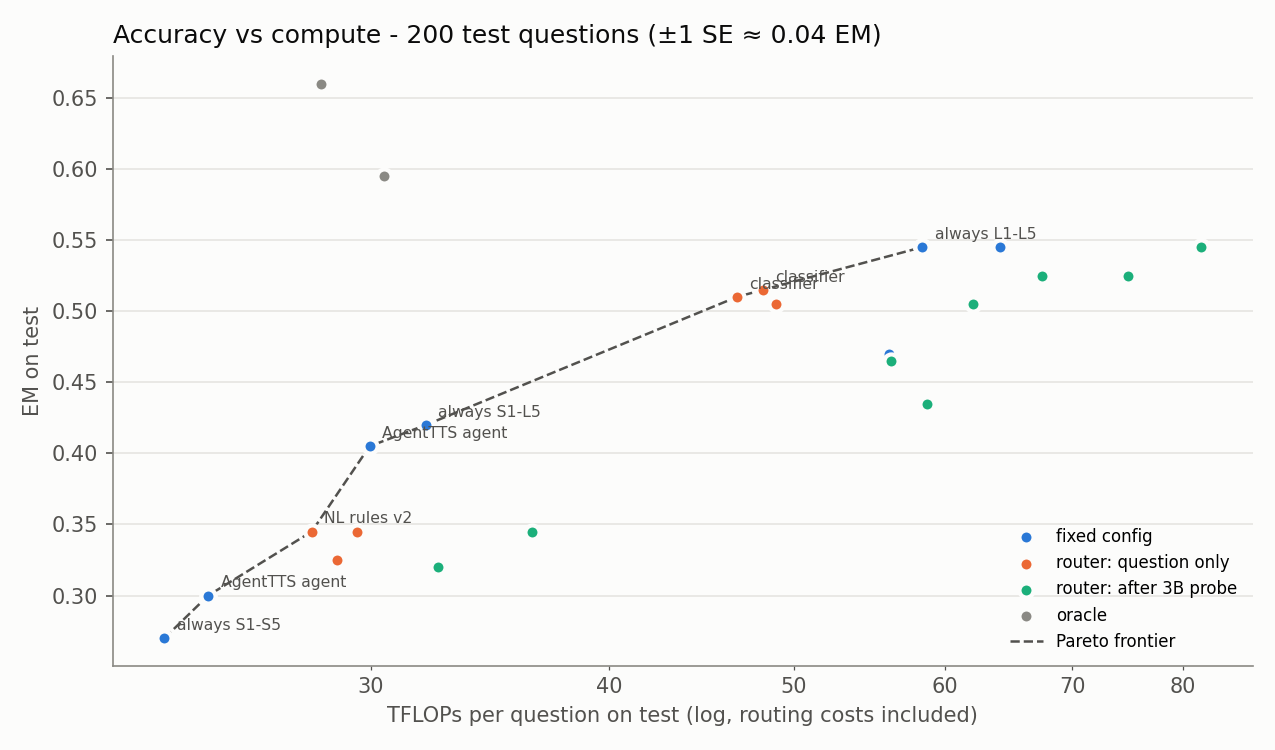

Wall-clock (s): {'install_vllm': 233, 'copy_models': 452, '01_switching': 407, '02_speedcheck': 305, 'total_notebook': 1397}

--- rules_v2_after_probe_lam0.03.txt ---
1. IF yesno = no AND compare = no AND words <= 15 AND digit = no AND names <= 3 AND agree <= 0.8 AND ret_agree <= 0.666667 THEN S1-S5
2. IF yesno = no AND compare = no AND words <= 15 AND digit = no AND names <= 3 AND agree <= 0.8 AND ret_agree > 0.666667 THEN S1-L5
3. IF yesno = no AND compare = no AND words <= 15 AND digit = no AND names > 3 AND agree <= 0.8 THEN S1-S5
4. IF yesno = no AND compare = no AND words <= 15 AND digit = no AND names > 3 AND agree > 0.8 THEN S1-L5
5. IF yesno = no AND compare = no AND words <= 15 AND digit = no AND agree <= 0.8 AND ret_agree <= 0.666667 AND names <= 3 THEN S1-S5
6. IF yesno = no AND compare = no AND words <= 15 AND digit = no AND agree <= 0.8 AND ret_agree > 0.666667 AND names <= 3 THEN S1-L5
7. IF yesno = no AND compare = no AND words <= 15 AND digit = no AND agree <= 0.8 AND 

,policy,setting,lambda,questions,mean_s,median_s,p95_s,EM
0,"always L1-L5 (retrieval 7B x1, answer 7B x5)",fixed,NaN,10,4.00,2.84,8.66,0.5
1,cascade (agree<1.01 -> L1-L5),after probe,0.00,10,5.06,4.67,7.23,0.4
2,classifier (cost-weighted),before running,0.00,10,3.21,2.97,5.42,0.4
3,dev-optimal global config,fixed,0.03,10,3.37,3.15,5.43,0.4


In [15]:
from IPython.display import Image, Markdown, display
for f in ["summary.md", "policies_em_vs_flops.png"]:
    p = f"{RUN_DIR}/{f}"
    if not os.path.exists(p):
        continue
    display(Markdown(open(p).read()) if p.endswith(".md") else Image(p))
TIMES["total_notebook"] = round(time.time() - T_START)
json.dump(TIMES, open(f"{RUN_DIR}/logs/stage_times.json", "w"), indent=1)
print("Wall-clock (s):", TIMES)
import glob as _g
for p in sorted(_g.glob(f"{RUN_DIR}/rules_v2_*.txt")):
    print(f"\n--- {os.path.basename(p)} ---\n" + open(p).read())
if os.path.exists(f"{RUN_DIR}/speedcheck.csv"):
    import pandas as pd
    display(pd.read_csv(f"{RUN_DIR}/speedcheck.csv").round(2))